<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/03_tree_decision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Team A7 - Predictive question (Decision Tree and Random Forest)
**Question:** Can the details on a San Francisco building permit application predict whether the project will be abandoned rather than completed?

**Context:** Of the 62,148 resolved San Francisco building permits filed between 2000 and 2013, about 36% were never completed (expired, cancelled or withdrawn). Abandoned projects waste DBI review and inspection time. If the risk of abandonment can be estimated at filing, DBI can prioritize high-risk permits for early outreach.

**Why this model:** a decision tree captures non-linear effects and interactions (e.g. "filed before 2003 and several plan sets") as readable yes/no rules. A single tree is unstable, so a random forest averages many trees for better accuracy and stability, at the cost of readability.

**Methodology:**
1. Use only the 23 features known at filing (loaded from `permits_data.py`), with a grouped 80/20 train/test split and grouped 5-fold cross-validation.
2. Build an unrestricted tree, compare split criteria (misclassification error, Gini, entropy), and tune depth and leaf size.
3. Tune a random forest and check its stability against a single tree.
4. Evaluate on ROC AUC, plus accuracy, recall and precision, against baselines.
5. Examine cutoffs and feature importance.

**Target:**
* `y = 1` if the permit did not finish (expired, cancelled, withdrawn, disapproved, revoked or denied)
* `y = 0` if completed
* Recall and precision therefore refer to failing permits.

In [1]:
# --- setup ---
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
pd.set_option('display.max_columns', 50)

## Data
Cleaning code lives in `permits_data.py`, so all models use the same rows, features, grouped train/test split and preprocessor.

In [2]:
# --- load the cleaning code from permits_data.py ---
# In Colab the file isn't there yet, so download it from the team GitHub repo first.
import os, urllib.request
if not os.path.exists('permits_data.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/seanyi-creator/ba-305-project/main/permits_data.py',
        'permits_data.py')

from permits_data import (load_permits, get_permit_data, make_cv, make_preprocessor,
                          NUMERIC, CATEGORICAL, RANDOM_STATE)

In [3]:
# --- first 5 rows of the raw dataset ---
raw = load_permits()
raw.head()

,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,unit,unit_suffix,description,status,status_date,filed_date,issued_date,completed_date,first_construction_document_date,structural_notification,number_of_existing_stories,number_of_proposed_stories,voluntary_soft_story_retrofit,fire_only_permit,permit_expiration_date,estimated_cost,revised_cost,existing_use,existing_units,proposed_use,proposed_units,plansets,tidf_compliance,existing_construction_type,existing_construction_type_description,proposed_construction_type,proposed_construction_type_description,site_permit,supervisor_district,neighborhoods_analysis_boundaries,zipcode,location,record_id,date
0,2000010368,3,additions alterations or repairs,2000-01-03T00:00:00Z,0113,025,9,NaN,Calhoun,Tr,NaN,NaN,convert 3unit into 2unit convert garage into l...,complete,2003-01-23T00:00:00Z,2000-01-03T00:00:00Z,2001-03-02T00:00:00Z,2003-01-23T00:00:00Z,NaN,NaN,2.0,2.0,NaN,NaN,2003-03-02T00:00:00Z,180000.0,480000.0,apartments,3.0,2 family dwelling,2.0,2.0,NaN,5.0,wood frame (5),5.0,wood frame (5),NaN,3.0,North Beach,94133.0,POINT (-122.40378074667099 37.80076017854741),76172259173,2000-01-03
1,2000010353,6,demolitions,2000-01-03T00:00:00Z,1785,001A,2921,NaN,Irving,St,NaN,NaN,demolish old barn building,complete,2000-06-21T00:00:00Z,2000-01-03T00:00:00Z,2000-04-06T00:00:00Z,2000-06-21T00:00:00Z,NaN,NaN,1.0,NaN,NaN,NaN,2000-10-03T00:00:00Z,NaN,NaN,storage shed,0.0,NaN,NaN,0.0,NaN,5.0,wood frame (5),NaN,NaN,NaN,4.0,Sunset/Parkside,94122.0,POINT (-122.48934486192445 37.76277580044787),761712114087,2000-01-03
2,2000010498,3,additions alterations or repairs,2000-01-04T00:00:00Z,3705,042,865,NaN,Market,St,NaN,NaN,one stop project tenant improvment at 865 mark...,complete,2000-02-23T00:00:00Z,2000-01-04T00:00:00Z,2000-02-02T00:00:00Z,2000-02-23T00:00:00Z,NaN,NaN,5.0,5.0,NaN,NaN,2002-02-02T00:00:00Z,317000.0,NaN,retail sales,0.0,retail sales,0.0,4.0,NaN,2.0,constr type 2,2.0,constr type 2,NaN,6.0,South of Market,94103.0,POINT (-122.40715841875158 37.783946952773675),761798164435,2000-01-04
3,2000010484,3,additions alterations or repairs,2000-01-04T00:00:00Z,6540,040,525,NaN,Jersey,St,NaN,NaN,"enclosing roof terrace, remodeling bedrooms an...",expired,2001-09-17T00:00:00Z,2000-01-04T00:00:00Z,2000-08-08T00:00:00Z,NaN,2000-08-14T00:00:00Z,Y,3.0,3.0,NaN,NaN,2001-08-08T00:00:00Z,140000.0,140000.0,1 family dwelling,1.0,1 family dwelling,1.0,2.0,NaN,5.0,wood frame (5),5.0,wood frame (5),Y,8.0,Noe Valley,94114.0,POINT (-122.43684279374855 37.75007564328008),761789206874,2000-01-04
4,2000010480,3,additions alterations or repairs,2000-01-04T00:00:00Z,0013,013,145,NaN,Jefferson,St,NaN,NaN,alt to (e) fire prot. system,complete,2000-07-13T00:00:00Z,2000-01-04T00:00:00Z,2000-03-01T00:00:00Z,2000-07-13T00:00:00Z,NaN,NaN,3.0,3.0,NaN,NaN,2001-03-01T00:00:00Z,50000.0,50000.0,food/beverage hndlng,0.0,food/beverage hndlng,0.0,2.0,NaN,2.0,constr type 2,2.0,constr type 2,NaN,NaN,NaN,94133.0,NaN,761785305125,2000-01-04


In [4]:
# --- load the shared split ---
X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data(raw)   # reuse the download from above
print(f'Train: {len(X_train):,} permits · Test: {len(X_test):,} permits')
print(f'Did not finish: {y_train.mean():.1%} of train, {y_test.mean():.1%} of test')

Train: 49,676 permits · Test: 12,472 permits
Did not finish: 35.7% of train, 36.7% of test


## Step 1 — Initial decision tree
An unrestricted tree (no depth or leaf-size limits), scored on the training folds and on grouped 5-fold cross-validation.

In [5]:
# Step 1 — unrestricted tree: training vs cross-validated scores
def tree_pipe(**kw):
    return Pipeline([('prep', make_preprocessor()),
                     ('model', DecisionTreeClassifier(random_state=RANDOM_STATE, **kw))])

cv = make_cv()
full = cross_validate(tree_pipe(), X_train, y_train, groups=groups_train, cv=cv,
                      scoring=['roc_auc', 'accuracy'], return_train_score=True, n_jobs=-1)
full_fit = tree_pipe().fit(X_train, y_train).named_steps['model']
print(f'Fully grown tree: depth {full_fit.get_depth()}, {full_fit.get_n_leaves():,} leaves '
      f'for {len(X_train):,} training permits')
pd.DataFrame({
    'training folds': [full['train_roc_auc'].mean(), full['train_accuracy'].mean(), 1 - full['train_accuracy'].mean()],
    'cross-validation folds': [full['test_roc_auc'].mean(), full['test_accuracy'].mean(), 1 - full['test_accuracy'].mean()],
}, index=['ROC AUC', 'accuracy', 'error rate']).round(3)

Fully grown tree: depth 66, 12,900 leaves for 49,676 training permits


,training folds,cross-validation folds
ROC AUC,1.000,0.585
accuracy,0.996,0.617
error rate,0.004,0.383


The tree grows to a depth of 66 with 12,900 leaves, about one leaf per four training permits. It fits the training data almost perfectly (AUC 1.000, error rate 0.4%), but its cross-validated AUC is 0.585 and its error rate 38.3%, worse than predicting "completed" for every permit (≈ 36% error). The unrestricted tree overfits, so the following steps constrain it.

## Step 2 — Split criterion
Three impurity measures can score a candidate split: misclassification error, the Gini index and entropy. We first compare all three on the first split of the tree, then compare Gini and entropy across tree depths.

In [6]:
# Step 2 — impurity measures and a helper that scores a split under each 
def misclassification_error(p):
    return 1 - np.maximum(p, 1 - p)

def gini(p):
    return 2 * p * (1 - p)

def entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

IMPURITY = {'misclassification error': misclassification_error, 'gini': gini, 'entropy': entropy}

def split_report(children):
    """children: list of (n_failed, n_completed) for each child node. Parent = their sum."""
    fail = sum(c[0] for c in children); n = sum(c[0] + c[1] for c in children)
    rows = {}
    for name, f in IMPURITY.items():
        before = f(fail / n)
        after = sum((a + b) / n * f(a / (a + b)) for a, b in children)
        rows[name] = {'parent impurity': before, 'children (weighted)': after, 'decrease': before - after}
    return pd.DataFrame(rows).T.round(4)

In [7]:
# Step 2 — the first split each criterion picks on our data 
prep_fit = make_preprocessor().fit(X_train)
Xt = prep_fit.transform(X_train)
feat_names = [n.replace('num__', '').replace('cat__', '') for n in prep_fit.get_feature_names_out()]
y_arr = y_train.to_numpy()
scaler = prep_fit.named_transformers_['num'].named_steps['scale']

def describe(f, thr):
    """Put the split in plain words (numeric thresholds are converted back from standardized units)."""
    name = feat_names[f]
    if f < len(NUMERIC):
        return f'{name} ≤ {thr * scaler.scale_[f] + scaler.mean_[f]:.2f}'
    return f'{name}: left = no, right = yes'          # a 0/1 column

rows, root_reports = [], {}
for crit in ['gini', 'entropy']:
    stump = DecisionTreeClassifier(max_depth=1, criterion=crit, random_state=RANDOM_STATE).fit(Xt, y_arr)
    f, thr = stump.tree_.feature[0], stump.tree_.threshold[0]
    left = Xt[:, f].toarray().ravel() <= thr
    children = [(int(y_arr[side].sum()), int((1 - y_arr[side]).sum())) for side in (left, ~left)]
    rep = split_report(children)
    rows.append({'criterion': crit, 'split chosen': describe(f, thr),
                 'left: n / % did not finish': f'{left.sum():,} / {y_arr[left].mean():.1%}',
                 'right: n / % did not finish': f'{(~left).sum():,} / {y_arr[~left].mean():.1%}',
                 **{f'decrease in {k}': v for k, v in rep['decrease'].items()}})
pd.DataFrame(rows).set_index('criterion').T

criterion,gini,entropy
split chosen,filing_year ≤ 2002.50,filing_year ≤ 2002.50
left: n / % did not finish,"19,769 / 43.1%","19,769 / 43.1%"
right: n / % did not finish,"29,907 / 30.9%","29,907 / 30.9%"
decrease in misclassification error,0.0,0.0
decrease in gini,0.0072,0.0072
decrease in entropy,0.0112,0.0112


Gini and entropy select the same first split: permits filed in 2002 or earlier (43.1% did not finish) versus 2003–2013 (30.9%). Under misclassification error this split has an impurity decrease of exactly 0, because both child nodes remain majority "completed" and the predicted class does not change. Misclassification error therefore cannot rank this split, or any split that leaves the majority class unchanged, so it is not used as a split criterion. It is reported instead as the error rate of the fitted models (Step 6).

The first split being the filing year reflects the decline in failure rates over time noted in `01_permits_prep`. Steps 8 and 9 examine this dependence.

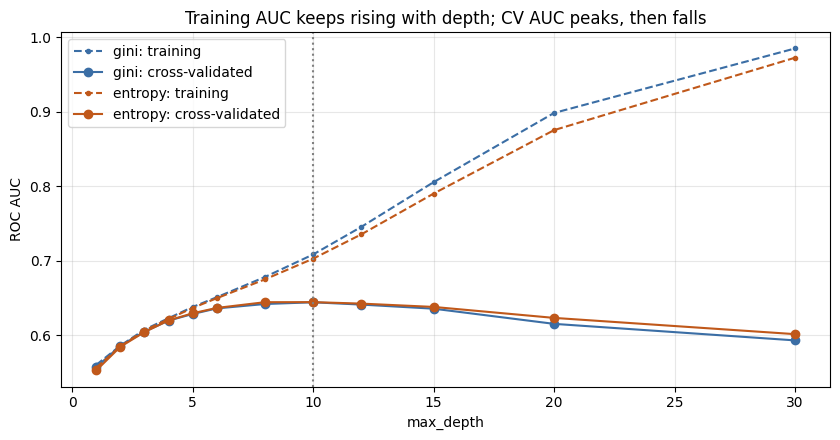

criterion,entropy,gini
max_depth,,
1,0.5531,0.5574
2,0.5848,0.5861
3,0.6045,0.6051
4,0.6201,0.6199
5,0.6297,0.6288
6,0.6369,0.6363
8,0.6446,0.6422
10,0.6447,0.6445
12,0.6427,0.6414


In [8]:
# Step 2 — training and CV AUC across depths, for both criteria 
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
curve = []
for crit in ['gini', 'entropy']:
    for d in depths:
        r = cross_validate(tree_pipe(criterion=crit, max_depth=d), X_train, y_train, groups=groups_train,
                           cv=cv, scoring='roc_auc', return_train_score=True, n_jobs=-1)
        curve.append({'criterion': crit, 'max_depth': d,
                      'training AUC': r['train_score'].mean(), 'CV AUC': r['test_score'].mean()})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for crit, color in [('gini', '#3b6ea5'), ('entropy', '#c0581a')]:
    c = curve[curve['criterion'] == crit]
    ax.plot(c['max_depth'], c['training AUC'], color=color, ls='--', marker='.', label=f'{crit}: training')
    ax.plot(c['max_depth'], c['CV AUC'], color=color, marker='o', label=f'{crit}: cross-validated')
best_row = curve.loc[curve['CV AUC'].idxmax()]
ax.axvline(best_row['max_depth'], color='grey', ls=':')
ax.set_xlabel('max_depth'); ax.set_ylabel('ROC AUC'); ax.grid(alpha=0.3); ax.legend()
ax.set_title('Training AUC keeps rising with depth; CV AUC peaks, then falls')
plt.tight_layout(); plt.show()
curve.pivot(index='max_depth', columns='criterion', values='CV AUC').round(4)

Cross-validated AUC rises from 0.55 at depth 1 to a peak of about 0.645 at depths 8–10, then falls to about 0.60 at depth 30 while training AUC approaches 0.98. Shallow trees underfit and deep trees overfit. Gini and entropy differ by less than 0.01 at every depth, so the choice between them is left to the grid search in Step 3.

## Step 3 — Hyperparameter tuning
Grid search over `criterion` (Gini, entropy), `max_depth` (6–20) and `min_samples_leaf` (1–800): 84 combinations, each scored by ROC AUC with grouped 5-fold cross-validation on the training set. `class_weight` is not tuned, as it has little effect on AUC (see `02_logistic`); the cutoff is chosen in Step 7.

In [9]:
# Step 3 — grid search for the decision tree 
tree_grid = {'model__criterion': ['gini', 'entropy'],
             'model__max_depth': [6, 8, 10, 12, 15, 20],
             'model__min_samples_leaf': [1, 20, 50, 100, 200, 400, 800]}
t0 = time.time()
tree_search = GridSearchCV(tree_pipe(), tree_grid, cv=cv, scoring='roc_auc',
                           return_train_score=True, n_jobs=-1)
tree_search.fit(X_train, y_train, groups=groups_train)
tree_res = pd.DataFrame(tree_search.cv_results_)
tree_time = tree_search.refit_time_
print(f'{len(tree_res)} combinations × 5 folds in {time.time() - t0:.0f}s')
print('Best:', tree_search.best_params_, '· CV AUC', round(tree_search.best_score_, 4))

best_crit = tree_search.best_params_['model__criterion']
(tree_res[tree_res['param_model__criterion'] == best_crit]
    .pivot_table(index='param_model__max_depth', columns='param_model__min_samples_leaf', values='mean_test_score')
    .round(4).rename_axis(index='max_depth', columns=f'min_samples_leaf  (criterion = {best_crit}, CV AUC)'))

84 combinations × 5 folds in 61s
Best: {'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 200} · CV AUC 0.6524


"min_samples_leaf (criterion = entropy, CV AUC)",1,20,50,100,200,400,800
max_depth,,,,,,,
6,0.6369,0.6373,0.6379,0.6384,0.6372,0.6350,0.6299
8,0.6446,0.6454,0.6459,0.6459,0.6457,0.6408,0.6353
10,0.6447,0.6449,0.6450,0.6470,0.6476,0.6430,0.6373
12,0.6427,0.6423,0.6481,0.6509,0.6507,0.6450,0.6372
15,0.6383,0.6404,0.6478,0.6505,0.6524,0.6446,0.6376
20,0.6236,0.6334,0.6454,0.6503,0.6517,0.6453,0.6376


In [10]:
# Step 3 — Gini vs entropy at their own best settings, and the train/CV gap of the winner 
best_by_crit = tree_res.loc[tree_res.groupby('param_model__criterion')['mean_test_score'].idxmax(),
                            ['param_model__criterion', 'param_model__max_depth', 'param_model__min_samples_leaf',
                             'mean_train_score', 'mean_test_score', 'std_test_score']]
best_by_crit.columns = ['criterion', 'max_depth', 'min_samples_leaf', 'training AUC', 'CV AUC', 'CV AUC (sd)']
best_by_crit.round(4).set_index('criterion')

,max_depth,min_samples_leaf,training AUC,CV AUC,CV AUC (sd)
criterion,,,,,
entropy,15,200,0.6785,0.6524,0.0047
gini,15,200,0.6779,0.6502,0.0054


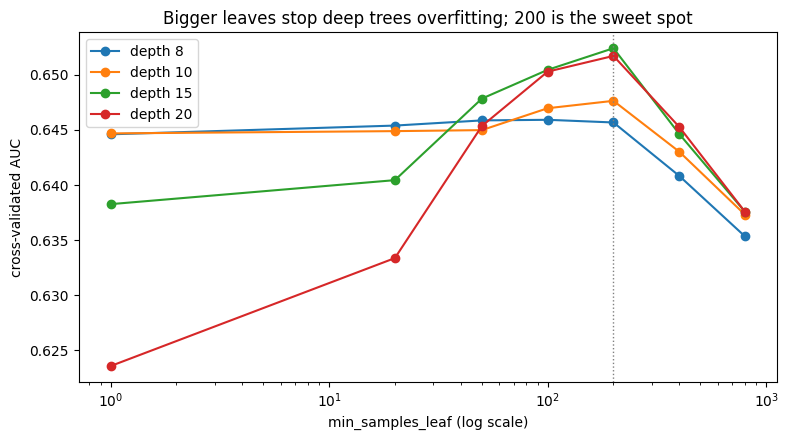

In [11]:
# --- Step 3 — CV AUC vs. minimum leaf size, one line per depth (entropy) ---
res = pd.DataFrame(tree_search.cv_results_)
res = res[res['param_model__criterion'] == 'entropy']
fig, ax = plt.subplots(figsize=(8, 4.5))
for d in [8, 10, 15, 20]:
    sub = res[res['param_model__max_depth'] == d].sort_values('param_model__min_samples_leaf')
    ax.plot(sub['param_model__min_samples_leaf'].astype(int), sub['mean_test_score'], marker='o', label=f'depth {d}')
ax.set_xscale('log'); ax.set_xlabel('min_samples_leaf (log scale)'); ax.set_ylabel('cross-validated AUC')
ax.axvline(200, color='grey', ls=':', lw=1)
ax.set_title('Bigger leaves stop deep trees overfitting; 200 is the sweet spot')
ax.legend(); plt.tight_layout(); plt.show()

- **Selected tree:** entropy, `max_depth = 15`, `min_samples_leaf = 200`, with a CV AUC of 0.652. Both values lie inside the searched range: depth 20 and leaf size 400 score lower.
- **Leaf size has the larger effect.** At depth 15, CV AUC rises from 0.638 (leaf size 1) to 0.652 (leaf size 200). A leaf size of 800 underfits (≈ 0.638).
- **Criterion:** Gini's best is 0.650, within one fold standard deviation (≈ 0.005) of entropy, so the two are effectively equivalent. Entropy is retained as the search's selection.
- **Fit:** training AUC 0.679 against CV AUC 0.652, a small gap.

## Step 4 — Decision rules
A depth-3 tree with the selected criterion and leaf size, fitted on unscaled inputs so that thresholds are in original units. Scaling does not change which splits a tree selects. Each node shows the share of training permits and the proportions [completed, did not finish]. Paler nodes are closer to 50/50.

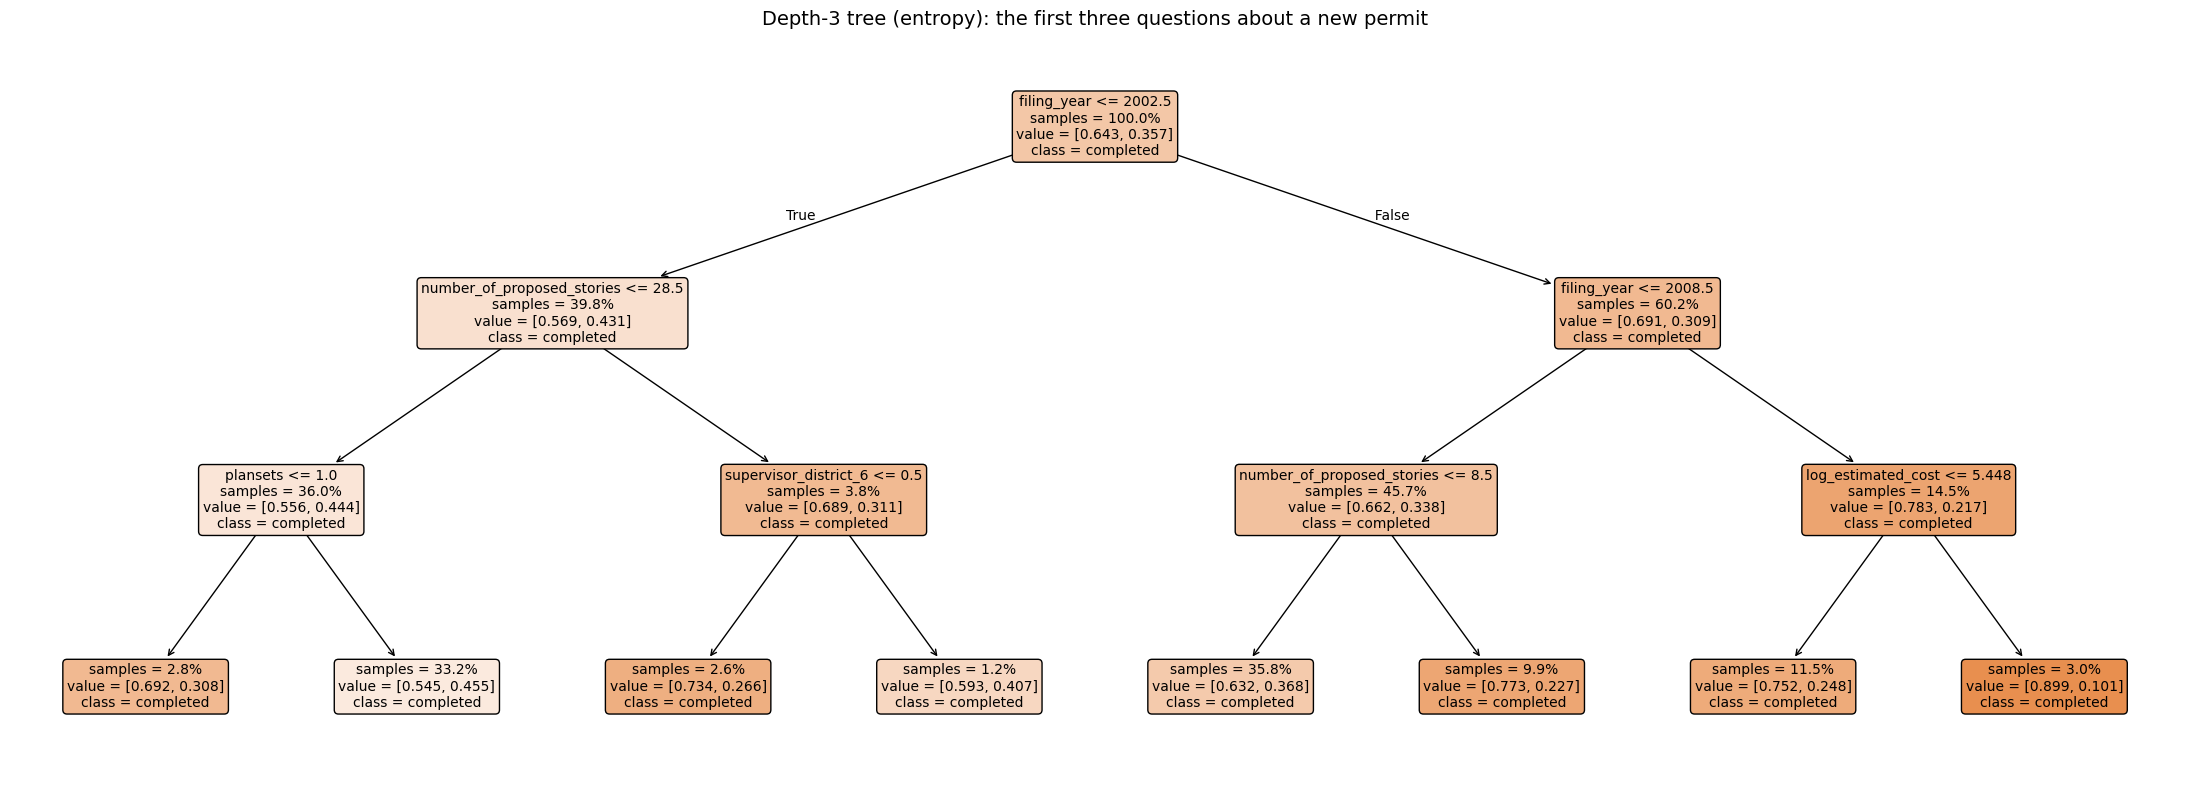

For reference, this depth-3 tree's test AUC is 0.605


In [12]:
# Step 4 — draw a depth-3 tree (unscaled numbers so thresholds are readable) 
def make_unscaled_preprocessor():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])

small_tree = Pipeline([('prep', make_unscaled_preprocessor()),
                       ('model', DecisionTreeClassifier(max_depth=3, criterion=best_crit,
                                                        min_samples_leaf=tree_search.best_params_['model__min_samples_leaf'],
                                                        random_state=RANDOM_STATE))]).fit(X_train, y_train)
small_names = [n.replace('num__', '').replace('cat__', '') for n in small_tree.named_steps['prep'].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(small_tree.named_steps['model'], feature_names=small_names, class_names=['completed', 'did not finish'],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=10, ax=ax)
ax.set_title(f'Depth-3 tree ({best_crit}): the first three questions about a new permit', fontsize=14)
plt.tight_layout(); plt.show()
print(f"For reference, this depth-3 tree's test AUC is {roc_auc_score(y_test, small_tree.predict_proba(X_test)[:, 1]):.3f}")

- **Filing year forms the first two levels:** 43% of permits filed before 2003 did not finish, against 34% for 2003–2008 and 22% for 2009–2013.
- **Highest-risk node:** filed before 2003 with more than one plan set (33% of permits), where 45.5% did not finish.
- **Lowest-risk node:** filed 2009–2013 with an estimated cost above about $280,000, where 10.1% did not finish.
- **Height:** among 2003–2008 permits, projects proposing more than 8 stories did not finish 22.7% of the time, against 36.8% for smaller projects.

Every leaf remains majority "completed", so the model's usefulness lies in its predicted probabilities rather than its class labels. The depth-3 tree reaches a test AUC of 0.605, against 0.644 for the tuned tree.

## Step 5 — Random forest
The forest is tuned in two rounds with grouped 5-fold cross-validation, using 100 trees per forest during tuning and the entropy criterion selected in Step 3:
1. `max_features` ∈ {sqrt, 0.1, 0.25, 0.4}, at `min_samples_leaf = 5`
2. `min_samples_leaf` ∈ {1, 5, 20}, at the best `max_features`

In [13]:
# Step 5 — round 1: max_features 
def forest_pipe(n_estimators=100, **kw):
    return Pipeline([('prep', make_preprocessor()),
                     ('model', RandomForestClassifier(n_estimators=n_estimators, criterion=best_crit,
                                                      random_state=RANDOM_STATE, n_jobs=-1, **kw))])

t0 = time.time()
rf_round1 = GridSearchCV(forest_pipe(min_samples_leaf=5), {'model__max_features': ['sqrt', 0.1, 0.25, 0.4]},
                         cv=cv, scoring='roc_auc', return_train_score=True)
rf_round1.fit(X_train, y_train, groups=groups_train)
best_mf = rf_round1.best_params_['model__max_features']
print(f'Round 1 in {time.time() - t0:.0f}s · best max_features = {best_mf}')
r1 = pd.DataFrame(rf_round1.cv_results_)
r1 = r1[['param_model__max_features', 'mean_train_score', 'mean_test_score', 'std_test_score']]
r1.columns = ['max_features', 'training AUC', 'CV AUC', 'CV AUC (sd)']
r1.round(4).set_index('max_features')

Round 1 in 109s · best max_features = 0.25


,training AUC,CV AUC,CV AUC (sd)
max_features,,,
sqrt,0.8418,0.6919,0.0051
0.1,0.8686,0.6948,0.0062
0.25,0.9395,0.6993,0.0060
0.4,0.9595,0.6987,0.0056


In [14]:
# Step 5 — round 2: min_samples_leaf at the best max_features 
t0 = time.time()
rf_round2 = GridSearchCV(forest_pipe(max_features=best_mf), {'model__min_samples_leaf': [1, 5, 20]},
                         cv=cv, scoring='roc_auc', return_train_score=True)
rf_round2.fit(X_train, y_train, groups=groups_train)
best_rf_kw = {'max_features': best_mf, 'min_samples_leaf': rf_round2.best_params_['model__min_samples_leaf']}
print(f'Round 2 in {time.time() - t0:.0f}s · best settings: {best_rf_kw} · CV AUC {rf_round2.best_score_:.4f}')
r2 = pd.DataFrame(rf_round2.cv_results_)
r2 = r2[['param_model__min_samples_leaf', 'mean_train_score', 'mean_test_score', 'std_test_score']]
r2.columns = ['min_samples_leaf', 'training AUC', 'CV AUC', 'CV AUC (sd)']
r2.round(4).set_index('min_samples_leaf')

Round 2 in 115s · best settings: {'max_features': 0.25, 'min_samples_leaf': 5} · CV AUC 0.6993


,training AUC,CV AUC,CV AUC (sd)
min_samples_leaf,,,
1,0.9997,0.6955,0.0046
5,0.9395,0.6993,0.0060
20,0.7962,0.6895,0.0044


- **Selected forest:** `max_features = 0.25` and `min_samples_leaf = 5`, with a CV AUC of 0.699. Both values are interior to the search: 0.4 (0.699) and leaf sizes 1 (0.696) and 20 (0.690) score lower.
- **Improvement over the single tree:** CV AUC rises from 0.652 to 0.699. The high training AUC (0.94) is expected for a forest and does not indicate a problem, because model selection relies on the CV score.

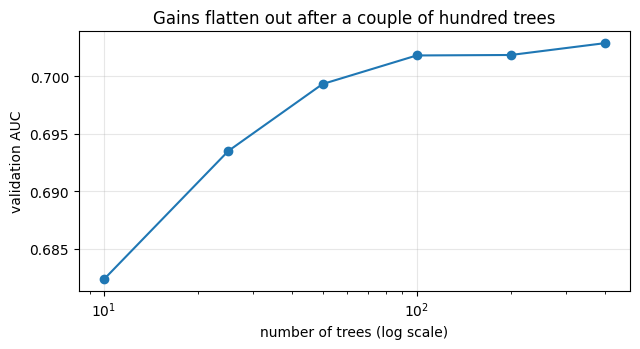

trees,10,25,50,100,200,400
validation AUC,0.6823,0.6935,0.6993,0.7018,0.7018,0.7029


In [15]:
# Step 5 — does adding trees help? (one grouped validation fold inside the training set) 
fit_idx, val_idx = next(cv.split(X_train, y_train, groups_train))
rf_prep = make_preprocessor().fit(X_train.iloc[fit_idx])
Xf, Xv = rf_prep.transform(X_train.iloc[fit_idx]), rf_prep.transform(X_train.iloc[val_idx])
forest = RandomForestClassifier(n_estimators=10, criterion=best_crit, warm_start=True,
                                random_state=RANDOM_STATE, n_jobs=-1, **best_rf_kw)
n_trees, val_auc = [10, 25, 50, 100, 200, 400], []
for n in n_trees:
    forest.set_params(n_estimators=n).fit(Xf, y_train.iloc[fit_idx])     # warm_start: adds trees
    val_auc.append(roc_auc_score(y_train.iloc[val_idx], forest.predict_proba(Xv)[:, 1]))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(n_trees, val_auc, marker='o'); ax.set_xscale('log')
ax.set_xlabel('number of trees (log scale)'); ax.set_ylabel('validation AUC'); ax.grid(alpha=0.3)
ax.set_title('Gains flatten out after a couple of hundred trees')
plt.tight_layout(); plt.show()
pd.DataFrame({'trees': n_trees, 'validation AUC': np.round(val_auc, 4)}).set_index('trees').T

Validation AUC levels off after about 100 trees (0.702 at 100 and 200, 0.703 at 400). The final forest uses 200 trees.

In [16]:
# Step 5 — the final forest: tuned settings, 200 trees, fitted on all training permits
best_rf = forest_pipe(n_estimators=200, **best_rf_kw)
t0 = time.time(); best_rf.fit(X_train, y_train); rf_time = time.time() - t0
print(f'Final forest: {best_rf_kw}, 200 trees · fitted in {rf_time:.0f}s')
print(f'Its CV AUC from tuning (100 trees): {rf_round2.best_score_:.4f}')

Final forest: {'max_features': 0.25, 'min_samples_leaf': 5}, 200 trees · fitted in 17s
Its CV AUC from tuning (100 trees): 0.6993


### Tree stability
A single tree can change substantially when the training data changes slightly, which makes its rules and predictions unreliable. We refit the tuned tree and the forest on five bootstrap samples of the training data, and compare their top splits and their agreement on a held-out validation fold.

In [17]:
# Step 5 — stability: tuned tree vs forest across five bootstrap samples of the training data
fit_idx, val_idx = next(cv.split(X_train, y_train, groups_train))
Xa, ya = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
Xv, yv = X_train.iloc[val_idx], y_train.iloc[val_idx]
best_tree_kw = {k.replace('model__', ''): v for k, v in tree_search.best_params_.items()}

def split_text(pipe, node):
    # the split at a given node, with numeric thresholds converted back to original units
    prep, t = pipe.named_steps['prep'], pipe.named_steps['model'].tree_
    names = [n.replace('num__', '').replace('cat__', '') for n in prep.get_feature_names_out()]
    f, thr = t.feature[node], t.threshold[node]
    if f < len(NUMERIC):
        sc = prep.named_transformers_['num'].named_steps['scale']
        return f'{names[f]} ≤ {thr * sc.scale_[f] + sc.mean_[f]:.1f}'
    return names[f]

rng = np.random.default_rng(RANDOM_STATE)
rows, tree_p, forest_p = [], [], []
for b in range(5):
    i = rng.integers(0, len(Xa), len(Xa))                                   # bootstrap sample
    tree = tree_pipe(**best_tree_kw).fit(Xa.iloc[i], ya.iloc[i])
    forest = Pipeline([('prep', make_preprocessor()),
                       ('model', RandomForestClassifier(n_estimators=100, criterion=best_crit, random_state=b,
                                                        n_jobs=-1, **best_rf_kw))]).fit(Xa.iloc[i], ya.iloc[i])
    t = tree.named_steps['model'].tree_
    tree_p.append(tree.predict_proba(Xv)[:, 1]); forest_p.append(forest.predict_proba(Xv)[:, 1])
    rows.append({'sample': b + 1, 'root split': split_text(tree, 0),
                 'left child split': split_text(tree, t.children_left[0]),
                 'right child split': split_text(tree, t.children_right[0]),
                 'tree AUC': roc_auc_score(yv, tree_p[-1]), 'forest AUC': roc_auc_score(yv, forest_p[-1])})
tree_p, forest_p = np.array(tree_p), np.array(forest_p)
pairs = np.triu_indices(5, 1)
print(f'Validation AUC range: tree {np.ptp([r["tree AUC"] for r in rows]):.3f}, '
      f'forest {np.ptp([r["forest AUC"] for r in rows]):.3f}')
print(f'Average correlation of predictions between samples: tree {np.corrcoef(tree_p)[pairs].mean():.2f}, '
      f'forest {np.corrcoef(forest_p)[pairs].mean():.2f}')
pd.DataFrame(rows).set_index('sample').round(3)

Validation AUC range: tree 0.017, forest 0.008
Average correlation of predictions between samples: tree 0.70, forest 0.84


,root split,left child split,right child split,tree AUC,forest AUC
sample,,,,,
1,filing_year ≤ 2001.5,number_of_proposed_stories ≤ 29.5,filing_year ≤ 2008.5,0.644,0.691
2,filing_year ≤ 2002.5,plansets ≤ 1.0,filing_year ≤ 2009.5,0.637,0.685
3,filing_year ≤ 2008.5,filing_year ≤ 2001.5,log_estimated_cost ≤ 4.7,0.639,0.687
4,filing_year ≤ 2002.5,number_of_proposed_stories ≤ 29.5,filing_year ≤ 2008.5,0.627,0.691
5,filing_year ≤ 2008.5,filing_year ≤ 2002.5,log_estimated_cost ≤ 5.5,0.636,0.683


- **The tree's structure is unstable.** Its root split moves between filing year ≤ 2001, 2002 and 2008 across samples, and the second-level splits change with it.
- **Its performance and predictions vary more than the forest's.** Tree validation AUC ranges from 0.627 to 0.644, against 0.683 to 0.691 for the forest. Predictions from different resamples correlate at about 0.70 for the tree, against 0.84 for the forest.

The forest is consistently both more accurate and more stable, which supports using it over a single tree.

## Step 6 — Model evaluation
The tuned tree and forest are scored once on the held-out test set, against the two baselines. The comparison with logistic regression and the neural network is in `05_model_comparison`.

In [18]:
# Step 6 — score the tuned tree and forest once on the test set
best_tree = tree_search.best_estimator_
models = {'Decision tree': best_tree, 'Random forest': best_rf}
cv_auc = {'Decision tree': tree_search.best_score_, 'Random forest': rf_round2.best_score_}

def scores(name, y_true, prob, pred, cv_value=np.nan):
    return {'model': name, 'CV AUC (train)': cv_value, 'test ROC AUC': roc_auc_score(y_true, prob),
            'accuracy': accuracy_score(y_true, pred), 'error rate': 1 - accuracy_score(y_true, pred),
            'recall': recall_score(y_true, pred, zero_division=0),
            'precision': precision_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0), 'share flagged': pred.mean()}

rows, probs = [], {}
for name, strategy in [('Baseline: always "completed"', 'most_frequent'), ('Baseline: random guess', 'stratified')]:
    d = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append(scores(name, y_test, d.predict_proba(X_test)[:, 1], d.predict(X_test)))
for name, m in models.items():
    probs[name] = m.predict_proba(X_test)[:, 1]
    rows.append(scores(name, y_test, probs[name], (probs[name] >= 0.5).astype(int), cv_auc[name]))
results = pd.DataFrame(rows).set_index('model').round(3)
results

,CV AUC (train),test ROC AUC,accuracy,error rate,recall,precision,F1,share flagged
model,,,,,,,,
"Baseline: always ""completed""",NaN,0.500,0.633,0.367,0.000,0.000,0.000,0.000
Baseline: random guess,NaN,0.498,0.538,0.462,0.349,0.365,0.357,0.351
Decision tree,0.652,0.644,0.639,0.361,0.248,0.519,0.336,0.176
Random forest,0.699,0.698,0.669,0.331,0.335,0.588,0.427,0.209


- **Test AUC:** random forest 0.698, decision tree 0.644, baselines 0.50.
- **CV and test AUC agree for both models,** so the tuning carries over to unseen data.
- **Error rate:** the forest's 33.1% is 3.6 points below the "always completed" baseline (36.7%); the tree's 36.1% barely improves on it.
- **At the 0.5 cutoff** the forest flags 21% of permits with 59% precision and 34% recall. The tree flags 18% with 52% precision and 25% recall.

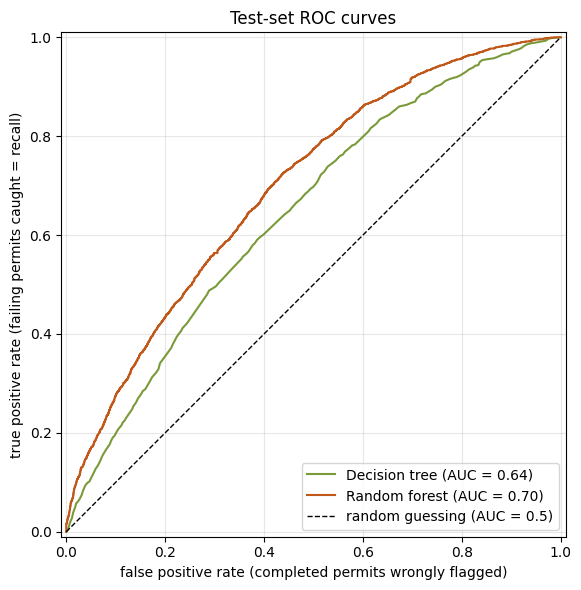

In [19]:
# Step 6 — ROC curves on the test set
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, pr), color in zip(probs.items(), ['#7a9a3a', '#c0581a']):
    RocCurveDisplay.from_predictions(y_test, pr, name=name, ax=ax, color=color)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random guessing (AUC = 0.5)')
ax.set_xlabel('false positive rate (completed permits wrongly flagged)')
ax.set_ylabel('true positive rate (failing permits caught = recall)')
ax.set_title('Test-set ROC curves'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Step 7 — Threshold selection
The cutoff is selected on out-of-fold training predictions for the random forest, under several assumed cost ratios between a missed failure and a false alarm, and then applied once to the test set.

Model used for flagging: Random forest


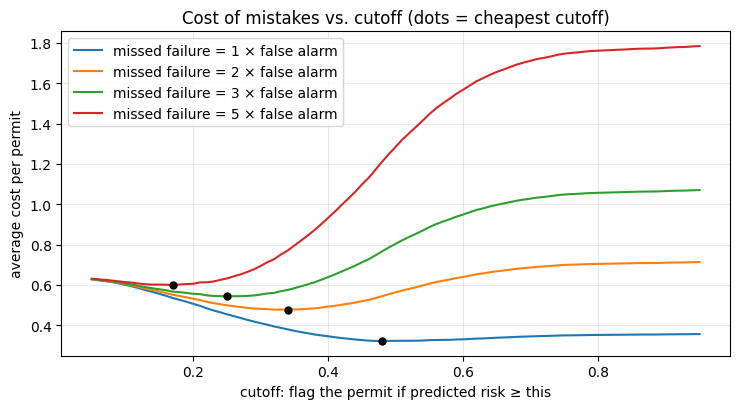

,cutoff (from training CV),test recall,test precision,share of permits flagged,test accuracy
cost ratio (miss : false alarm),,,,,
1 : 1,0.48,0.383,0.573,0.246,0.668
2 : 1,0.34,0.724,0.490,0.543,0.622
3 : 1,0.25,0.876,0.446,0.723,0.554
5 : 1,0.17,0.960,0.409,0.862,0.476


In [20]:
# Step 7 — pick the cutoff on out-of-fold training predictions 
chosen = 'Random forest'   # best CV AUC in this notebook
print('Model used for flagging:', chosen)
oof = cross_val_predict(models[chosen], X_train, y_train, groups=groups_train, cv=cv, method='predict_proba')[:, 1]

cutoffs = np.round(np.arange(0.05, 0.96, 0.01), 2)
def expected_cost(y_true, prob, cut, fn_cost, fp_cost=1):
    pred = prob >= cut
    fn = ((y_true == 1) & ~pred).sum(); fp = ((y_true == 0) & pred).sum()
    return (fn_cost * fn + fp_cost * fp) / len(y_true)

rows = []
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for ratio in [1, 2, 3, 5]:
    cost = [expected_cost(y_train.to_numpy(), oof, c, ratio) for c in cutoffs]
    cut = cutoffs[int(np.argmin(cost))]
    ax.plot(cutoffs, cost, label=f'missed failure = {ratio} × false alarm')
    ax.plot(cut, min(cost), 'ko', ms=5)
    pred = (probs[chosen] >= cut).astype(int)                      # applied once to the test set
    rows.append({'cost ratio (miss : false alarm)': f'{ratio} : 1', 'cutoff (from training CV)': cut,
                 'test recall': recall_score(y_test, pred), 'test precision': precision_score(y_test, pred),
                 'share of permits flagged': pred.mean(), 'test accuracy': accuracy_score(y_test, pred)})
ax.set_xlabel('cutoff: flag the permit if predicted risk ≥ this'); ax.set_ylabel('average cost per permit')
ax.set_title('Cost of mistakes vs. cutoff (dots = cheapest cutoff)'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
cutoff_table = pd.DataFrame(rows).set_index('cost ratio (miss : false alarm)').round(3)
cutoff_table

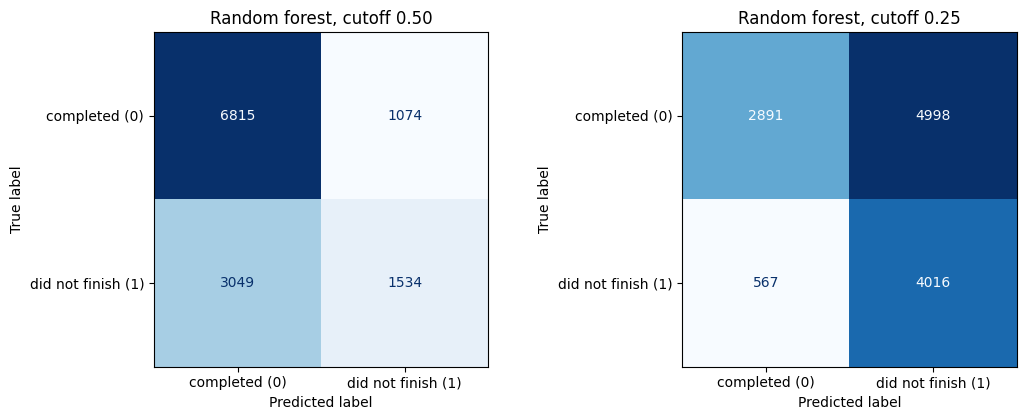

In [21]:
# Step 7 — confusion matrices: default 0.5 vs. the 3 : 1 cost cutoff 
cut3 = cutoff_table.loc['3 : 1', 'cutoff (from training CV)']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, cut in zip(axes, [0.5, cut3]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probs[chosen] >= cut).astype(int),
                                            display_labels=['completed (0)', 'did not finish (1)'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{chosen}, cutoff {cut:.2f}')
plt.tight_layout(); plt.show()

An alternative criterion is review capacity: the share of failures captured if staff review a fixed share of the highest-risk permits.

In [22]:
# Step 7 — flag the riskiest k% of test permits 
rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.50]:
    cut = np.quantile(probs[chosen], 1 - k)
    pred = (probs[chosen] >= cut).astype(int)
    rows.append({'review the riskiest': f'{k:.0%}', 'failures caught (recall)': recall_score(y_test, pred),
                 'flagged that really fail (precision)': precision_score(y_test, pred),
                 'lift over random review': precision_score(y_test, pred) / y_test.mean()})
pd.DataFrame(rows).set_index('review the riskiest').round(3)

,failures caught (recall),flagged that really fail (precision),lift over random review
review the riskiest,,,
5%,0.101,0.740,2.015
10%,0.177,0.650,1.768
20%,0.321,0.590,1.606
30%,0.451,0.552,1.502
50%,0.676,0.497,1.353


- **Cost-based cutoffs:** a 1:1 cost ratio gives a cutoff of 0.48. At 3:1 the cutoff falls to 0.25, which flags 72% of permits, catches 88% of failures and has 45% precision. At higher cost ratios the model flags most permits, which is of limited practical use.
- **Capacity-based selection:** the riskiest 10% of permits have 65% precision (1.8 times the 36.7% base rate) and capture 18% of failures. The riskiest 5% have 74% precision.

The model is best suited to prioritizing outreach rather than screening permits.

## Step 8 — Feature importance
Permutation importance on the test set: the decrease in AUC when each of the 23 original features is randomly shuffled.

computed in 11s


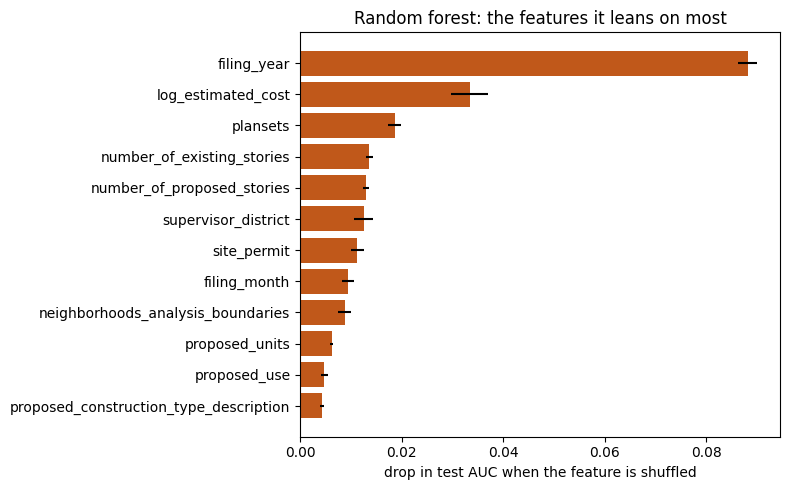

,feature,AUC drop (mean),AUC drop (sd)
0,filing_year,0.0882,0.0019
1,log_estimated_cost,0.0334,0.0036
2,plansets,0.0186,0.0012
3,number_of_existing_stories,0.0136,0.0006
4,number_of_proposed_stories,0.0130,0.0006
5,supervisor_district,0.0126,0.0019
6,site_permit,0.0113,0.0014
7,filing_month,0.0094,0.0011
8,neighborhoods_analysis_boundaries,0.0088,0.0013
9,proposed_units,0.0062,0.0003


In [23]:
# Step 8 — permutation importance on the test set (drop in AUC when a feature is shuffled)
t0 = time.time()
perm = permutation_importance(best_rf, X_test, y_test, scoring='roc_auc', n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({'feature': X_test.columns, 'AUC drop (mean)': perm.importances_mean,
                     'AUC drop (sd)': perm.importances_std})
       .sort_values('AUC drop (mean)', ascending=False).reset_index(drop=True))
print(f'computed in {time.time() - t0:.0f}s')
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top['feature'], top['AUC drop (mean)'], xerr=top['AUC drop (sd)'], color='#c0581a')
ax.set_xlabel('drop in test AUC when the feature is shuffled')
ax.set_title('Random forest: the features it leans on most')
plt.tight_layout(); plt.show()
imp.round(4)

- **Filing year is the dominant feature** (AUC decrease 0.088).
- **Project scale follows:** estimated cost (0.033), plan sets (0.019) and number of stories (≈ 0.013 each).
- **Location and site permit status come next;** permit type and use changes contribute little.

Correlated features, such as existing and proposed stories or district and neighborhood, share importance and therefore each appear less influential.

In [24]:
# Step 8 — how much of the signal is just "when was it filed"? Refit the forest without filing_year/filing_month
NO_DATE = [c for c in NUMERIC if c not in ('filing_year', 'filing_month')]
def prep_without_dates():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', numeric, NO_DATE), ('cat', categorical, CATEGORICAL)])

no_date_rf = Pipeline([('prep', prep_without_dates()),
                       ('model', RandomForestClassifier(n_estimators=200, criterion=best_crit, random_state=RANDOM_STATE,
                                                        n_jobs=-1, **best_rf_kw))]).fit(X_train, y_train)
print(f"Random forest test AUC with dates: {roc_auc_score(y_test, probs['Random forest']):.3f}")
print(f"Random forest test AUC without filing year/month: {roc_auc_score(y_test, no_date_rf.predict_proba(X_test)[:, 1]):.3f}")

Random forest test AUC with dates: 0.698
Random forest test AUC without filing year/month: 0.655


Without filing year and month, the forest's test AUC falls from 0.698 to 0.655.
- **The forest still finds signal without the date variables,** well above the 0.50 baselines.
- **Filing year accounts for a substantial share of the signal.** Permits filed after 2013 lie outside the training range, and trees cannot extrapolate beyond it, so 0.655 is the more conservative estimate of performance on new permits. Validation on later permits, for all models, is in `05_model_comparison`, Step 7.

## Step 9 — Conclusions
1. **The random forest outperforms the single tree,** with a test AUC of 0.698 against 0.644, and the lowest error rate (33.1%).
2. **Gini and entropy perform equivalently.** Misclassification error is unsuitable as a split criterion on this data.
3. **Tuning substantially improved the tree:** CV AUC rose from 0.585 unrestricted to 0.652 tuned. The single tree remains unstable across resamples, while the forest is more stable.
4. **The riskiest 10% of permits fail at 65%,** against a 37% base rate, which supports prioritizing outreach but not denying or delaying permits.
5. **Filing year is the dominant feature;** without the date variables the forest's AUC falls to 0.655.

How the tree and forest compare with logistic regression and the neural network, including on later permits, is in `05_model_comparison`.

**Limitations**
- Much of the signal comes from filing year (Step 8). The model covers permits filed 2000–2013 only and would need retraining on recent data.
- The cost ratios in Step 7 are assumptions.
- Results are associations, not causal effects.